## **IMPLEMENTASI PYTHON PADA PERMASALAHAN PROBABILITAS**

In [ ]:
import math, itertools, random
import statistics as stat
from scipy import stats as st
from fractions import Fraction
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

rng = np.random.default_rng(42)
random.seed(42)
pd.options.display.float_format = "{:.4f}".format

def info(teks):
    print("\nInterpretasi:", teks)

#### **MATERI 1 - Ruang Sampel, Titik Sampel, dan Kejadian**
#### Studi kasus 1a: status 3 server
**Soal:** Sebuah klaster memiliki 3 server (S1, S2, S3). Setiap server berstatus *U* (up) atau *D* (down). Tentukan ruang sampel, lalu hitung peluang kejadian:
- A: paling sedikit 2 server down
- B: semua server up
- C: tepat 2 server down

Dengan asumsi setiap titik sampel sama mungkin: P(E) = n(E) / n(S).

In [ ]:
S = list(itertools.product(["U", "D"], repeat=3))
print("Ruang sampel S =", S)
print("n(S) =", len(S))

A = [s for s in S if s.count("D") >= 2]
B = [s for s in S if s.count("D") == 0]
C = [s for s in S if s.count("D") == 2]

for nama, E in [("A (>=2 down)", A), ("B (semua up)", B), ("C (tepat 2 down)", C)]:
    print(f"\n{nama}: {E}")
    print(f"  P = {len(E)}/{len(S)} = {Fraction(len(E), len(S))} = {len(E)/len(S):.4f}")

info(f"""Ada {len(S)} kemungkinan status klaster.
Peluang paling sedikit 2 server down adalah {len(A)/len(S):.0%}.
Angka ini hanya layak sebagai model belajar karena mengasumsikan U dan D sama mungkin,
sedangkan server nyata jauh lebih sering up daripada down.""")

Ruang sampel S = [('U', 'U', 'U'), ('U', 'U', 'D'), ('U', 'D', 'U'), ('U', 'D', 'D'), ('D', 'U', 'U'), ('D', 'U', 'D'), ('D', 'D', 'U'), ('D', 'D', 'D')]
n(S) = 8

A (>=2 down): [('U', 'D', 'D'), ('D', 'U', 'D'), ('D', 'D', 'U'), ('D', 'D', 'D')]
  P = 4/8 = 1/2 = 0.5000

B (semua up): [('U', 'U', 'U')]
  P = 1/8 = 1/8 = 0.1250

C (tepat 2 down): [('U', 'D', 'D'), ('D', 'U', 'D'), ('D', 'D', 'U')]
  P = 3/8 = 3/8 = 0.3750

Interpretasi: Ada 8 kemungkinan status klaster. 
Peluang paling sedikit 2 server down adalah 50%. 
Angka ini hanya layak sebagai model belajar karena mengasumsikan U dan D sama mungkin, 
sedangkan server nyata jauh lebih sering up daripada down.


#### Studi kasus 1b: pengiriman 2 bit data
**Soal:** Sebuah sensor mengirim 2 bit berurutan (0 atau 1). Berapa peluang kedua bit bernilai sama?
Pada pelemparan koin 2 kali, kejadian "sama" adalah {(T,T), (H,H)} sehingga P = 2/4 = 50%.

In [ ]:
S2 = list(itertools.product([0, 1], repeat=2))
sama = [s for s in S2 if s[0] == s[1]]
p_sama = Fraction(len(sama), len(S2))
print("Ruang sampel:", S2)
print("Kejadian 'kedua bit sama':", sama)
print("P(sama) =", p_sama, "=", float(p_sama), "=", f"{float(p_sama):.0%}")

info(f"""Dari {len(S2)} pola bit, {len(sama)} pola berisi bit kembar
sehingga peluangnya {float(p_sama):.0%}.
Hasil ini sama dengan perhitungan manual (2/4 = 1/2).""")

Ruang sampel: [(0, 0), (0, 1), (1, 0), (1, 1)]
Kejadian 'kedua bit sama': [(0, 0), (1, 1)]
P(sama) = 1/2 = 0.5 = 50%

Interpretasi: Dari 4 pola bit, 2 pola berisi bit kembar 
sehingga peluangnya 50%.
Hasil ini sama dengan perhitungan manual (2/4 = 1/2).


#### **MATERI 2 - Tiga Pendekatan Probabilitas (Klasik, Empiris, Subjektif)**
#### Studi kasus 2a: pendekatan klasik (tebakan PIN 4 digit)
**Soal:** Seorang penyerang menebak PIN 4 digit (0000-9999) secara acak. Hitung (a) peluang tebakan pertama benar dan (b) peluang digit pertama PIN genap.
Pendekatan klasik: semua hasil sama mungkin, P(A) = n(A) / n(total).

In [ ]:
total = 10 ** 4
p_benar = Fraction(1, total)
genap = sum(1 for pin in itertools.product(range(10), repeat=4) if pin[0] % 2 == 0)
p_genap = Fraction(genap, total)

print(f"(a) P(tebakan pertama benar) = {p_benar} = {float(p_benar):.4%}")
print(f"(b) PIN dengan digit pertama genap = {genap} dari {total} -> P = {float(p_genap):.2f}")

info(f"""Peluang menebak PIN sekali coba hanya {float(p_benar):.2%} (1 dari {total:,}).
PIN 4 digit tanpa pembatasan percobaan masih lemah karena seluruh kemungkinan hanya 10.000
dan bisa dicoba otomatis.""")

(a) P(tebakan pertama benar) = 1/10000 = 0.0100%
(b) PIN dengan digit pertama genap = 5000 dari 10000 -> P = 0.50

Interpretasi: Peluang menebak PIN sekali coba hanya 0.01% (1 dari 10,000).
PIN 4 digit tanpa pembatasan percobaan masih lemah karena seluruh kemungkinan hanya 10.000
dan bisa dicoba otomatis.


#### Studi kasus 2b: pendekatan empiris (data waktu respons API)
**Soal:** Sebuah layanan e-commerce mencatat 100.000 request API pada 26/10/2026. Waktu respons dikelompokkan dalam tabel frekuensi. Hitung P(respons < 100 ms) dan P(respons > 300 ms).
Pendekatan empiris: P(A) = f(A) / n.

In [ ]:
tabel = pd.DataFrame({
    "Interval respons (ms)": ["0-100", "100-200", "200-300", "300-400", "400-500"],
    "Frekuensi": [80000, 10000, 5000, 3000, 2000],
})
n = tabel["Frekuensi"].sum()
tabel["P relatif"] = tabel["Frekuensi"] / n
tabel["Persen (%)"] = tabel["P relatif"] * 100
print(tabel.to_string(index=False))
print("\nTotal request =", n, "| jumlah P =", tabel["P relatif"].sum())

p_cepat = tabel.loc[0, "Frekuensi"] / n
under300 = tabel.loc[0:2, "Frekuensi"].sum()
p_lambat = tabel.loc[3:4, "Frekuensi"].sum() / n
print(f"\nP(respons < 100 ms) = {p_cepat:.2f}")
print(f"P(respons > 300 ms) = {p_lambat:.2f}")

info(f"""{p_cepat:.0%} request selesai di bawah 100 ms dan {p_lambat:.0%} lebih lambat dari 300 ms.
Jika SLA mensyaratkan minimal 95% request di bawah 300 ms, data ini {'memenuhi' if under300/n >= 0.95 else 'tidak memenuhi'} SLA ({under300/n:.0%}).
Angka ini tepat berada pada batas, sehingga tim perlu waspada.""")

Interval respons (ms)  Frekuensi  P relatif  Persen (%)
                0-100      80000     0.8000     80.0000
              100-200      10000     0.1000     10.0000
              200-300       5000     0.0500      5.0000
              300-400       3000     0.0300      3.0000
              400-500       2000     0.0200      2.0000

Total request = 100000 | jumlah P = 1.0

P(respons < 100 ms) = 0.80
P(respons > 300 ms) = 0.05

Interpretasi: 80% request selesai di bawah 100 ms dan 5% lebih lambat dari 300 ms.
Jika SLA mensyaratkan minimal 95% request di bawah 300 ms, data ini memenuhi SLA (95%).
Angka ini tepat berada pada batas, sehingga tim perlu waspada.


#### Studi kasus 2c: pendekatan empiris dengan tabel frekuensi (keterlambatan build CI/CD)
**Soal:** Selama 30 jadwal build otomatis (CI/CD) dicatat keterlambatan mulainya build (menit). Frekuensi untuk keterlambatan 1 s.d. 10 menit adalah 2, 3, 8, 4, 5, 3, 2, 0, 1, 2. Hitung frekuensi relatif, P(keterlambatan <= 3 menit), P(keterlambatan >= 8 menit), dan rata-rata keterlambatan.

 Menit  Frekuensi  Frek. relatif  Kumulatif
     1          2         0.0667     0.0667
     2          3         0.1000     0.1667
     3          8         0.2667     0.4333
     4          4         0.1333     0.5667
     5          5         0.1667     0.7333
     6          3         0.1000     0.8333
     7          2         0.0667     0.9000
     8          0         0.0000     0.9000
     9          1         0.0333     0.9333
    10          2         0.0667     1.0000

Jumlah frekuensi = 30 | jumlah frek. relatif = 1.0

P(<= 3 menit) = 0.4333
P(>= 8 menit) = 0.1000
Rata-rata keterlambatan = 4.47 menit
Cek dengan library statistics: mean = 4.47 | median = 4.0 | modus = 3 menit

Interpretasi: Keterlambatan paling sering 3 menit (27%). 
Peluang build terlambat paling lama 3 menit adalah 43.3%, 
dan peluang terlambat 8 menit atau lebih 10.0%. Rata-rata 4.47 menit. 

Karena hanya 30 pengamatan, estimasi ini kasar, semakin banyak data semakin stabil 
(lihat Eksplorasi T3).


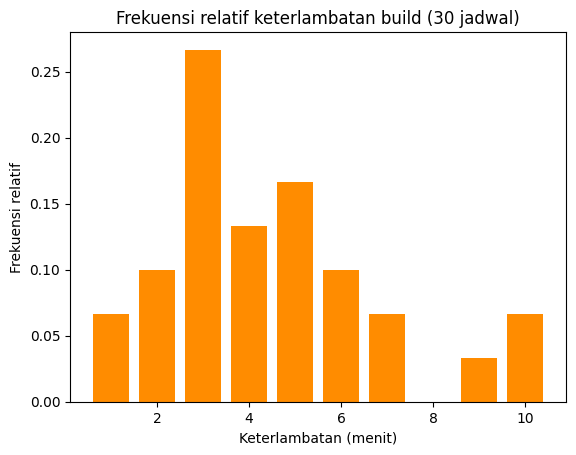

In [ ]:
menit = np.arange(1, 11)
frek = np.array([2, 3, 8, 4, 5, 3, 2, 0, 1, 2])
fr = frek / frek.sum()
tb = pd.DataFrame({"Menit": menit, "Frekuensi": frek, "Frek. relatif": fr, "Kumulatif": np.cumsum(fr)})
print(tb.to_string(index=False))
print("\nJumlah frekuensi =", frek.sum(), "| jumlah frek. relatif =", round(fr.sum(), 4))

p_le3 = fr[menit <= 3].sum()
p_ge8 = fr[menit >= 8].sum()
rata = (menit * fr).sum()
print(f"\nP(<= 3 menit) = {p_le3:.4f}")
print(f"P(>= 8 menit) = {p_ge8:.4f}")
print(f"Rata-rata keterlambatan = {rata:.2f} menit")

data_mentah = [int(m) for m, f in zip(menit, frek) for _ in range(f)]   # data asli 30 pengamatan
print(f"Cek dengan library statistics: mean = {stat.mean(data_mentah):.2f} | median = {stat.median(data_mentah)} | modus = {stat.mode(data_mentah)} menit")

info(f"""Keterlambatan paling sering 3 menit (27%).
Peluang build terlambat paling lama 3 menit adalah {p_le3:.1%},
dan peluang terlambat 8 menit atau lebih {p_ge8:.1%}. Rata-rata {rata:.2f} menit.

Karena hanya 30 pengamatan, estimasi ini kasar, semakin banyak data semakin stabil
(lihat Eksplorasi T3).""")

plt.bar(menit, fr, color="darkorange")
plt.title("Frekuensi relatif keterlambatan build (30 jadwal)")
plt.xlabel("Keterlambatan (menit)")
plt.ylabel("Frekuensi relatif")
plt.show()

#### Studi kasus 2d: pendekatan subjektif (estimasi pakar)
**Soal:** Tim menilai peluang rilis aplikasi tepat waktu. Tech Lead menilai 80%, Senior Developer 65%, dan QA Lead 55%. Tentukan estimasi peluang gabungan (a) rata-rata biasa dan (b) rata-rata berbobot pengalaman 0,5 : 0,3 : 0,2.
Pendekatan subjektif: peluang berasal dari penilaian pakar, bukan dari data atau hitungan hasil sama mungkin.

In [ ]:
pakar = {"Tech Lead": 0.80, "Senior Dev": 0.65, "QA Lead": 0.55}
bobot = np.array([0.5, 0.3, 0.2])
nilai = np.array(list(pakar.values()))

p_rata = nilai.mean()
p_bobot = (nilai * bobot).sum()
print("Penilaian pakar:", pakar)
print(f"(a) Rata-rata biasa   = {p_rata:.4f}")
print(f"(b) Rata-rata berbobot = {p_bobot:.4f}")

info(f"""Estimasi peluang rilis tepat waktu sekitar {p_rata:.0%} (biasa) atau {p_bobot:.1%} (berbobot).
Angka ini opini terstruktur, bukan fakta.

Layak dipakai sebagai peluang awal saat belum ada data, lalu sebaiknya
diperbarui dengan data sprint nyata (teorema Bayes, Materi 9).""")

Penilaian pakar: {'Tech Lead': 0.8, 'Senior Dev': 0.65, 'QA Lead': 0.55}
(a) Rata-rata biasa   = 0.6667
(b) Rata-rata berbobot = 0.7050

Interpretasi: Estimasi peluang rilis tepat waktu sekitar 67% (biasa) atau 70.5% (berbobot). 
Angka ini opini terstruktur, bukan fakta. 

Layak dipakai sebagai peluang awal saat belum ada data, lalu sebaiknya 
diperbarui dengan data sprint nyata (teorema Bayes, Materi 9).


#### **MATERI 3 - Diagram Venn: Kejadian Saling Lepas dan Tidak Saling Lepas**
#### Studi kasus: pengguna fitur Chat, Video Call, dan Voice Note
**Soal:** Sebuah aplikasi memiliki 100 pengguna (nomor 0-99). A = pengguna fitur Chat (nomor 0-59), B = pengguna Video Call (nomor 40-79), C = pengguna Voice Note (nomor 80-99). Tentukan apakah A dan B saling lepas, apakah A dan C saling lepas, hitung P(A ∪ B) dan P(A ∪ C), lalu gambarkan diagram Venn-nya.

Saling lepas: A ∩ B = kosong, sehingga P(A ∪ B) = P(A) + P(B).
Tidak saling lepas: P(A ∪ B) = P(A) + P(B) - P(A ∩ B).

A dan B saling lepas? False | |A irisan B| = 20
A dan C saling lepas? True | |A irisan C| = 0

P(A) = 0.60 | P(B) = 0.40 | P(C) = 0.20
P(A U B) = P(A)+P(B)-P(A irisan B) = 0.80 | hitung langsung = 0.80
P(A U C) = P(A)+P(C)              = 0.80 | hitung langsung = 0.80


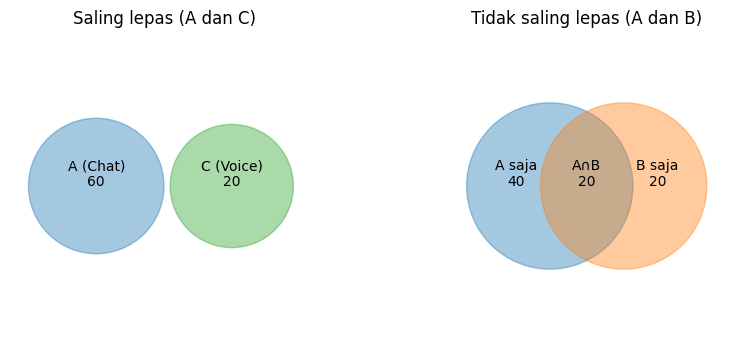


Interpretasi: A dan C tidak punya anggota bersama, jadi peluangnya cukup dijumlahkan (P(A U C) = 80%). 
A dan B beririsan 20 pengguna; bila hanya dijumlahkan hasilnya 100% 
(salah karena 20 pengguna terhitung dua kali), sedangkan yang benar 80%. 
Artinya 20 pengguna memakai Chat sekaligus Video Call.


In [ ]:
from matplotlib.patches import Circle

semua = set(range(100))
A = set(range(0, 60))     # pengguna Chat
B = set(range(40, 80))    # pengguna Video Call
C = set(range(80, 100))   # pengguna Voice Note
P = lambda E: len(E) / len(semua)

print("A dan B saling lepas?", A.isdisjoint(B), "| |A irisan B| =", len(A & B))
print("A dan C saling lepas?", A.isdisjoint(C), "| |A irisan C| =", len(A & C))
print(f"\nP(A) = {P(A):.2f} | P(B) = {P(B):.2f} | P(C) = {P(C):.2f}")
print(f"P(A U B) = P(A)+P(B)-P(A irisan B) = {P(A)+P(B)-P(A&B):.2f} | hitung langsung = {P(A|B):.2f}")
print(f"P(A U C) = P(A)+P(C)              = {P(A)+P(C):.2f} | hitung langsung = {P(A|C):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].add_patch(Circle((0.28, 0.5), 0.22, color="tab:blue", alpha=0.4))
ax[0].add_patch(Circle((0.72, 0.5), 0.20, color="tab:green", alpha=0.4))
ax[0].text(0.28, 0.5, f"A (Chat)\n{len(A)}", ha="center"); ax[0].text(0.72, 0.5, f"C (Voice)\n{len(C)}", ha="center")
ax[0].set_title("Saling lepas (A dan C)")
ax[1].add_patch(Circle((0.38, 0.5), 0.27, color="tab:blue", alpha=0.4))
ax[1].add_patch(Circle((0.62, 0.5), 0.27, color="tab:orange", alpha=0.4))
ax[1].text(0.27, 0.5, f"A saja\n{len(A-B)}", ha="center"); ax[1].text(0.5, 0.5, f"A∩B\n{len(A&B)}", ha="center")
ax[1].text(0.73, 0.5, f"B saja\n{len(B-A)}", ha="center")
ax[1].set_title("Tidak saling lepas (A dan B)")
for a in ax:
    a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal"); a.axis("off")
plt.show()

info(f"""A dan C tidak punya anggota bersama, jadi peluangnya cukup dijumlahkan (P(A U C) = {P(A|C):.0%}).
A dan B beririsan {len(A&B)} pengguna; bila hanya dijumlahkan hasilnya {P(A)+P(B):.0%}
(salah karena {len(A&B)} pengguna terhitung dua kali), sedangkan yang benar {P(A|B):.0%}.
Artinya {len(A&B)} pengguna memakai Chat sekaligus Video Call.""")

#### **MATERI 4 - Komplemen Kejadian**
#### Studi kasus: peluang minimal satu dari 5 server down
**Soal:** Sebuah sistem memakai 5 server independen. Peluang tiap server up dalam satu jam adalah 0,99. Hitung peluang paling sedikit satu server down. Gunakan P(A) = 1 - P(A^c) dan buktikan dengan simulasi.

In [ ]:
p_up, m = 0.99, 5
p_semua_up = p_up ** m
p_min1_down = 1 - p_semua_up
print(f"P(semua up)          = {p_semua_up:.4f}")
print(f"P(minimal 1 down)    = 1 - {p_semua_up:.4f} = {p_min1_down:.4f}")

N = 200000
sim = (rng.random((N, m)) < p_up).all(axis=1)
print(f"Simulasi {N} jam: P(semua up) = {sim.mean():.4f} | P(minimal 1 down) = {1 - sim.mean():.4f}")

info(f"""Walaupun tiap server 99% andal, peluang minimal satu server bermasalah mencapai {p_min1_down:.1%}
(sekitar 1 dari {round(1/p_min1_down)} jam). Hasil simulasi sangat dekat dengan hitungan teoritis,
sehingga rumus komplemen valid.
Pelajaran: makin banyak komponen, makin besar peluang ada yang gagal.""")

P(semua up)          = 0.9510
P(minimal 1 down)    = 1 - 0.9510 = 0.0490
Simulasi 200000 jam: P(semua up) = 0.9510 | P(minimal 1 down) = 0.0490

Interpretasi: Walaupun tiap server 99% andal, peluang minimal satu server bermasalah mencapai 4.9% 
(sekitar 1 dari 20 jam). Hasil simulasi sangat dekat dengan hitungan teoritis, 
sehingga rumus komplemen valid. 
Pelajaran: makin banyak komponen, makin besar peluang ada yang gagal.


#### **MATERI 5 - Irisan Kejadian (A ∩ B)**
#### Studi kasus 5a: irisan kejadian independen (server aplikasi dan database down bersamaan)
**Soal:** Peluang server aplikasi down adalah 2% dan peluang server database down adalah 5%, keduanya independen. Hitung peluang keduanya down bersamaan. Independen: P(A ∩ B) = P(A) x P(B).

In [ ]:
pA, pB = 0.02, 0.05
p_irisan = pA * pB
print(f"P(A irisan B) = {pA} x {pB} = {p_irisan:.4f} = {p_irisan:.2%}")
N = 1000000
sim = ((rng.random(N) < pA) & (rng.random(N) < pB)).mean()
print(f"Simulasi {N} percobaan = {sim:.4f}")

info(f"""Peluang kedua server down bersamaan hanya {p_irisan:.2%} (1 dari {round(1/p_irisan)} kejadian).
Karena independen, redundansi dua komponen menurunkan risiko secara drastis.
Simulasi mendekati nilai teoritis.""")

P(A irisan B) = 0.02 x 0.05 = 0.0010 = 0.10%
Simulasi 1000000 percobaan = 0.0010

Interpretasi: Peluang kedua server down bersamaan hanya 0.10% (1 dari 1000 kejadian). 
Karena independen, redundansi dua komponen menurunkan risiko secara drastis. 
Simulasi mendekati nilai teoritis.


#### Studi kasus 5b: irisan kejadian bersyarat (pengguna premium yang memakai 2FA)
**Soal:** Sebuah aplikasi memiliki 100.000 pengguna dan 2.000 di antaranya pengguna premium. Sebanyak 60% pengguna premium mengaktifkan autentikasi dua faktor (2FA). Berapa peluang seorang pengguna acak adalah premium dan mengaktifkan 2FA?
Bersyarat: P(A ∩ B) = P(A | B) x P(B). Hitungannya: 60% x 2000/100.000 = 1,2%.

In [ ]:
p_premium = Fraction(2000, 100000)
p_2fa_given_premium = Fraction(60, 100)
p_both = p_2fa_given_premium * p_premium
print(f"P(premium) = {p_premium} = {float(p_premium):.2%}")
print(f"P(2FA | premium) = {p_2fa_given_premium} = {float(p_2fa_given_premium):.0%}")
print(f"P(premium dan 2FA) = {p_both} = {float(p_both):.2%}")
print("Jumlah pengguna premium + 2FA =", int(p_both * 100000))

info(f"""Sebanyak {float(p_both):.1%} dari seluruh pengguna (sekitar {int(p_both*100000):,} orang) adalah premium sekaligus memakai 2FA.
Hasil ini sama dengan hitungan manual (12/1000 = 1,2%). Angka kecil karena irisan
dibatasi oleh kelompok premium yang hanya 2%.""")

P(premium) = 1/50 = 2.00%
P(2FA | premium) = 3/5 = 60%
P(premium dan 2FA) = 3/250 = 1.20%
Jumlah pengguna premium + 2FA = 1200

Interpretasi: Sebanyak 1.2% dari seluruh pengguna (sekitar 1,200 orang) adalah premium sekaligus memakai 2FA. 
Hasil ini sama dengan hitungan manual (12/1000 = 1,2%). Angka kecil karena irisan 
dibatasi oleh kelompok premium yang hanya 2%.


#### **MATERI 6 - Gabungan Kejadian (A ∪ B)**
#### Studi kasus 6a: gabungan kejadian saling lepas (bit kembar atau berbeda)
**Soal:** Dua bit dikirim. Kejadian A = kedua bit kembar {00, 11}, B = kedua bit berbeda {01, 10}. Hitung P(A ∪ B). Karena A dan B tidak beririsan, P(A ∪ B) = P(A) + P(B).

In [ ]:
S2 = set(itertools.product([0, 1], repeat=2))
A = {s for s in S2 if s[0] == s[1]}
B = {s for s in S2 if s[0] != s[1]}
P = lambda E: Fraction(len(E), len(S2))
print("A =", sorted(A), "| B =", sorted(B))
print("A irisan B =", A & B, "(kosong -> saling lepas)")
print(f"P(A) = {P(A)}, P(B) = {P(B)}")
print(f"P(A U B) = P(A)+P(B) = {P(A) + P(B)} | langsung dari himpunan = {P(A | B)}")

info(f"""P(A U B) = {float(P(A | B)):.0%}.
Kejadian 'kembar atau berbeda' mencakup seluruh ruang sampel sehingga pasti terjadi.
Hasil ini sesuai rumus saling lepas.""")

A = [(0, 0), (1, 1)] | B = [(0, 1), (1, 0)]
A irisan B = set() (kosong -> saling lepas)
P(A) = 1/2, P(B) = 1/2
P(A U B) = P(A)+P(B) = 1 | langsung dari himpunan = 1

Interpretasi: P(A U B) = 100%. 
Kejadian 'kembar atau berbeda' mencakup seluruh ruang sampel sehingga pasti terjadi. 
Hasil ini sesuai rumus saling lepas.


#### Studi kasus 6b: gabungan kejadian tidak saling lepas (ada bit 1 dan semua bit 1)
**Soal:** Dua bit dikirim. A = ada bit 1 (setidaknya satu), B = semua bit 1 (11). Hitung P(A ∪ B) memakai P(A) + P(B) - P(A ∩ B).

In [ ]:
S2 = set(itertools.product([0, 1], repeat=2))
P = lambda E: Fraction(len(E), len(S2))
A = {s for s in S2 if 1 in s}
B = {s for s in S2 if s == (1, 1)}
print("A =", sorted(A), "| B =", sorted(B), "| A irisan B =", sorted(A & B))
print(f"P(A) = {P(A)}, P(B) = {P(B)}, P(A irisan B) = {P(A & B)}")
rumus = P(A) + P(B) - P(A & B)
print(f"P(A U B) = {P(A)} + {P(B)} - {P(A & B)} = {rumus} = {float(rumus):.0%}")
print("Cek dari himpunan gabungan:", P(A | B))

info(f"""Jika irisan tidak dikurangkan, hasilnya {float(P(A) + P(B)):.0%}.
Itu salah karena titik sampel (1,1) terhitung dua kali (pola (0,0) tidak termasuk A maupun B, jadi gabungan tidak mungkin 100%).
Setelah irisan dikurangkan, P(A U B) = {float(rumus):.0%}, sama dengan perhitungan langsung.""")

A = [(0, 1), (1, 0), (1, 1)] | B = [(1, 1)] | A irisan B = [(1, 1)]
P(A) = 3/4, P(B) = 1/4, P(A irisan B) = 1/4
P(A U B) = 3/4 + 1/4 - 1/4 = 3/4 = 75%
Cek dari himpunan gabungan: 3/4

Interpretasi: Jika irisan tidak dikurangkan, hasilnya 100%. 
Itu salah karena titik sampel (1,1) terhitung dua kali (pola (0,0) tidak termasuk A maupun B, jadi gabungan tidak mungkin 100%). 
Setelah irisan dikurangkan, P(A U B) = 75%, sama dengan perhitungan langsung.


#### **MATERI 7 - Probabilitas Bersyarat**
#### Studi kasus 7a: status server berantai
**Soal:** Data log menunjukkan: error setelah hari error = 0,444; normal setelah error = 0,556; normal setelah normal = 0,724; error setelah normal = 0,276. Jika hari ini server error, berapa peluang dua hari berikutnya juga error? Berapa peluang hari ke-2 error (hari ke-1 bebas)?

In [ ]:
# urutan keadaan: 0 = Error, 1 = Normal
T = np.array([[0.444, 0.556],
              [0.276, 0.724]])
print("Jumlah tiap baris (harus 1):", T.sum(axis=1))

p_dua_hari_error = T[0, 0] * T[0, 0]
print(f"\nP(E hari-1 dan E hari-2 | E hari-0) = 0.444 x 0.444 = {p_dua_hari_error:.4f}")

T2 = np.linalg.matrix_power(T, 2)
print(f"P(E pada hari-2 | E hari-0), hari-1 bebas = {T2[0, 0]:.4f}")

info(f"""Jika hari ini error, peluang error dua hari berturut-turut berikutnya {p_dua_hari_error:.1%}.
Peluang hari ke-2 error tanpa mempedulikan hari ke-1 lebih besar ({T2[0,0]:.1%})
karena mencakup jalur normal lalu error.
Hasil sesuai diagram pohon (0,444 x 0,444 = 0,1971).""")

Jumlah tiap baris (harus 1): [1. 1.]

P(E hari-1 dan E hari-2 | E hari-0) = 0.444 x 0.444 = 0.1971
P(E pada hari-2 | E hari-0), hari-1 bebas = 0.3506

Interpretasi: Jika hari ini error, peluang error dua hari berturut-turut berikutnya 19.7%. 
Peluang hari ke-2 error tanpa mempedulikan hari ke-1 lebih besar (35.1%) 
karena mencakup jalur normal lalu error. 
Hasil sesuai diagram pohon (0,444 x 0,444 = 0,1971).


#### Studi kasus 7b: probabilitas bersyarat dari tabel silang (platform dan laporan bug)
**Soal:** Dari 1.000 pengguna, dicatat platform dan laporan bug. Android: 60 melapor bug dan 340 tidak. iOS: 30 melapor bug dan 570 tidak. Hitung P(bug | Android), P(bug | iOS), dan periksa apakah platform dan bug independen.

In [ ]:
tab = pd.DataFrame({"Bug": [60, 30], "Tidak bug": [340, 570]}, index=["Android", "iOS"])
tab["Total"] = tab.sum(axis=1)
tab.loc["Total"] = tab.sum()
print(tab)

N = tab.loc["Total", "Total"]
P_bug = tab.loc["Total", "Bug"] / N
P_and = tab.loc["Android", "Total"] / N
P_and_bug = tab.loc["Android", "Bug"] / N
P_bug_android = P_and_bug / P_and
P_bug_ios = tab.loc["iOS", "Bug"] / tab.loc["iOS", "Total"]
print(f"\nP(bug)           = {P_bug:.4f}")
print(f"P(bug | Android) = {P_and_bug:.4f} / {P_and:.4f} = {P_bug_android:.4f}")
print(f"P(bug | iOS)     = {P_bug_ios:.4f}")
print(f"P(Android dan bug) = {P_and_bug:.4f} | P(Android) x P(bug) = {P_and * P_bug:.4f}")

info(f"""Pengguna Android punya peluang melapor bug {P_bug_android:.0%}, tiga kali lipat iOS ({P_bug_ios:.0%}).
Karena P(Android dan bug) = {P_and_bug:.3f} tidak sama dengan P(Android) x P(bug) = {P_and*P_bug:.3f},
platform dan bug TIDAK independen. Tim sebaiknya memprioritaskan perbaikan di Android.""")

         Bug  Tidak bug  Total
Android   60        340    400
iOS       30        570    600
Total     90        910   1000

P(bug)           = 0.0900
P(bug | Android) = 0.0600 / 0.4000 = 0.1500
P(bug | iOS)     = 0.0500
P(Android dan bug) = 0.0600 | P(Android) x P(bug) = 0.0360

Interpretasi: Pengguna Android punya peluang melapor bug 15%, tiga kali lipat iOS (5%). 
Karena P(Android dan bug) = 0.060 tidak sama dengan P(Android) x P(bug) = 0.036, 
platform dan bug TIDAK independen. Tim sebaiknya memprioritaskan perbaikan di Android.


#### **MATERI 8 - Probabilitas Total**
#### Studi kasus: peluang request timeout
**Soal:** Peluang request timeout adalah 0,80 saat beban tinggi dan 0,25 saat beban normal. Peluang beban tinggi adalah 0,36. Berapa peluang timeout secara keseluruhan? Kemudian kembangkan ke 3 level beban: rendah (peluang 0,50, timeout 0,05), sedang (0,30; 0,20), tinggi (0,20; 0,60).
P(A) = jumlah dari P(B_i) x P(A | B_i).

In [ ]:
# Dua partisi (sesuai modul)
p_tinggi, p_timeout_tinggi, p_timeout_normal = 0.36, 0.80, 0.25
p_timeout = p_tinggi * p_timeout_tinggi + (1 - p_tinggi) * p_timeout_normal
print(f"P(timeout) = 0.36 x 0.80 + 0.64 x 0.25 = {p_timeout:.3f}")

# Tiga partisi
prior = np.array([0.50, 0.30, 0.20])
likelihood = np.array([0.05, 0.20, 0.60])
print("\nJumlah prior =", prior.sum(), "(partisi harus berjumlah 1)")
p_total = np.dot(prior, likelihood)
print("Kontribusi tiap level:", prior * likelihood)
print(f"P(timeout) 3 level = {p_total:.3f}")

info(f"""Secara keseluruhan {p_timeout:.1%} request timeout pada model 2 level, dan {p_total:.1%} pada model 3 level.
Keduanya dua skenario berbeda (distribusi beban dan peluang timeout tidak sama),
tidak untuk dibandingkan.""")

P(timeout) = 0.36 x 0.80 + 0.64 x 0.25 = 0.448

Jumlah prior = 1.0 (partisi harus berjumlah 1)
Kontribusi tiap level: [0.025 0.06  0.12 ]
P(timeout) 3 level = 0.205

Interpretasi: Secara keseluruhan 44.8% request timeout pada model 2 level, dan 20.5% pada model 3 level. 
Keduanya dua skenario berbeda (distribusi beban dan peluang timeout tidak sama), 
tidak untuk dibandingkan.


#### **MATERI 9 - Teorema Bayes**
#### Studi kasus: sumber error pada 4 node load balancer
**Soal:** Sebuah request dapat ditangani 4 node (R1-R4) dengan porsi trafik 0,1; 0,2; 0,3; 0,4. Peluang error di tiap node: 0,10; 0,15; 0,20; 0,25. Jika diketahui terjadi error, berapa peluang error itu berasal dari node 2? Hitung juga untuk node lain.
Bayes: P(R_j | E) = P(R_j) P(E | R_j) / jumlah P(R_i) P(E | R_i).

In [ ]:
prior = np.array([0.1, 0.2, 0.3, 0.4])
lik = np.array([0.10, 0.15, 0.20, 0.25])
joint = prior * lik
p_E = joint.sum()
post = joint / p_E

tb = pd.DataFrame({"Node": ["R1", "R2", "R3", "R4"], "P(Ri)": prior, "P(E|Ri)": lik,
                   "P(Ri)P(E|Ri)": joint, "P(Ri|E)": post})
print(tb.to_string(index=False))
print(f"\nP(E) = {p_E:.2f} | jumlah posterior = {post.sum():.2f}")
print(f"P(R2 | E) = {post[1]:.2f}")

info(f"""Peluang error berasal dari node 2 adalah {post[1]:.0%}.
Node 4 paling mungkin menjadi sumber ({post[3]:.0%}) karena menangani trafik
terbesar dan error rate tertinggi. Rata-rata error sistem {p_E:.0%}.
Tim operasi sebaiknya memeriksa node 4 lebih dulu.""")

Node  P(Ri)  P(E|Ri)  P(Ri)P(E|Ri)  P(Ri|E)
  R1 0.1000   0.1000        0.0100   0.0500
  R2 0.2000   0.1500        0.0300   0.1500
  R3 0.3000   0.2000        0.0600   0.3000
  R4 0.4000   0.2500        0.1000   0.5000

P(E) = 0.20 | jumlah posterior = 1.00
P(R2 | E) = 0.15

Interpretasi: Peluang error berasal dari node 2 adalah 15%. 
Node 4 paling mungkin menjadi sumber (50%) karena menangani trafik 
terbesar dan error rate tertinggi. Rata-rata error sistem 20%. 
Tim operasi sebaiknya memeriksa node 4 lebih dulu.


#### **MATERI 10 - Permutasi (Urutan Diperhatikan)**
#### Studi kasus 10a: permutasi dengan pengembalian, n^r
**Soal:** (a) Dari 4 server (A, B, C, D), dipilih 2 tugas berurutan dan server boleh dipilih lagi (hasil yang diharapkan: 16). (b) Password 8 karakter dari 62 karakter (huruf besar, kecil, angka): berapa kombinasinya, dan berapa lama brute force jika 1 miliar tebakan per detik?

In [ ]:
hasil_a = list(itertools.product("ABCD", repeat=2))
print("(a) Hasil itertools.product :", len(hasil_a), "pasangan ->", hasil_a)
print("    Rumus n^r = 4^2          =", 4 ** 2)

total_pw = 62 ** 8
detik = total_pw / 1e9
print(f"\n(b) Jumlah password 62^8 = {total_pw:,}")
print(f"    Waktu terburuk (seluruh ruang dicoba) = {detik:,.0f} detik = {detik/3600:,.1f} jam = {detik/86400:,.2f} hari")
print(f"    Waktu rata-rata (sekitar separuh ruang) = {detik/2/86400:,.2f} hari")

info(f"""Ada 16 pasangan, sama dengan rumus 4^2. Password 8 karakter memiliki sekitar {total_pw:.2e} kemungkinan.

Pada 1 miliar tebakan/detik (serangan offline), password 8 karakter habis dicoba
dalam sekitar 2,5 hari, rata-rata sekitar 1,3 hari, sehingga tidak aman.
Serangan online yang dibatasi jauh lebih lambat.""")


(a) Hasil itertools.product : 16 pasangan -> [('A', 'A'), ('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'A'), ('B', 'B'), ('B', 'C'), ('B', 'D'), ('C', 'A'), ('C', 'B'), ('C', 'C'), ('C', 'D'), ('D', 'A'), ('D', 'B'), ('D', 'C'), ('D', 'D')]
    Rumus n^r = 4^2          = 16

(b) Jumlah password 62^8 = 218,340,105,584,896
    Waktu terburuk (seluruh ruang dicoba) = 218,340 detik = 60.7 jam = 2.53 hari
    Waktu rata-rata (sekitar separuh ruang) = 1.26 hari

Interpretasi: Ada 16 pasangan, sama dengan rumus 4^2. Password 8 karakter memiliki sekitar 2.18e+14 kemungkinan. 

Pada 1 miliar tebakan/detik (serangan offline), password 8 karakter habis dicoba 
dalam sekitar 2,5 hari, rata-rata sekitar 1,3 hari, sehingga tidak aman. 
Serangan online yang dibatasi jauh lebih lambat.


#### Studi kasus 10b: permutasi tanpa pengembalian, P(n, r) = n! / (n - r)!
**Soal:** (a) Dari 4 server dipilih 2 sebagai primary lalu backup (urutan penting, tanpa pengulangan; hasil yang diharapkan: 12). (b) Dari 5 anggota tim dipilih Ketua, Sekretaris, dan Bendahara. Berapa susunan yang mungkin?

In [ ]:
print("(a) itertools.permutations:", len(list(itertools.permutations("ABCD", 2))))
print("    math.perm(4,2)        =", math.perm(4, 2), "| manual 4!/(4-2)! =", math.factorial(4) // math.factorial(2))
print("    Contoh:", list(itertools.permutations("ABCD", 2))[:5], "...")

print("\n(b) math.perm(5,3) =", math.perm(5, 3))
anggota = ["Ani", "Budi", "Cici", "Dedi", "Eka"]
for i, s in enumerate(itertools.permutations(anggota, 3)):
    if i < 3:
        print("   ", dict(zip(["Ketua", "Sekretaris", "Bendahara"], s)))

info(f"""Ada {math.perm(4,2)} cara menetapkan primary-backup dan {math.perm(5,3)} susunan pengurus.

Urutan penting: (A sebagai primary, B backup) berbeda dengan (B primary, A backup).
Hasil Python sama dengan rumus P(n, r).""")

(a) itertools.permutations: 12
    math.perm(4,2)        = 12 | manual 4!/(4-2)! = 12
    Contoh: [('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'A'), ('B', 'C')] ...

(b) math.perm(5,3) = 60
    {'Ketua': 'Ani', 'Sekretaris': 'Budi', 'Bendahara': 'Cici'}
    {'Ketua': 'Ani', 'Sekretaris': 'Budi', 'Bendahara': 'Dedi'}
    {'Ketua': 'Ani', 'Sekretaris': 'Budi', 'Bendahara': 'Eka'}

Interpretasi: Ada 12 cara menetapkan primary-backup dan 60 susunan pengurus. 

Urutan penting: (A sebagai primary, B backup) berbeda dengan (B primary, A backup). 
Hasil Python sama dengan rumus P(n, r).


#### **MATERI 11 - Kombinasi (Urutan Tidak Diperhatikan) dan Pendekatan Stirling**
#### Studi kasus 11a: kombinasi tanpa pengembalian, C(n, r)
**Soal:** (a) Dari 4 server dipilih 2 untuk di-upgrade (urutan tidak penting; hasil yang diharapkan: 6). (b) Dari 10 kandidat tester dipilih 3 orang. Berapa kombinasi, dan berapa peluang seorang kandidat tertentu terpilih?

In [ ]:
print("(a) combinations:", list(itertools.combinations("ABCD", 2)))
print("    math.comb(4,2) =", math.comb(4, 2))

total = math.comb(10, 3)
terpilih = math.comb(9, 2)   # satu orang pasti ada, pilih 2 lagi dari 9
print(f"\n(b) C(10,3) = {total}")
print(f"    Kombinasi yang memuat kandidat tertentu = C(9,2) = {terpilih}")
print(f"    P(terpilih) = {terpilih}/{total} = {Fraction(terpilih, total)} = {terpilih/total:.2f}")
print(f"    Cek dengan scipy.stats.hypergeom: {st.hypergeom.pmf(1, 10, 1, 3):.2f}")

info(f"""Ada {math.comb(4,2)} pasang server untuk di-upgrade dan {total} kemungkinan tim tester.

Peluang satu kandidat terpilih {terpilih/total:.0%}, sama dengan r/n = 3/10, yang masuk akal
karena seleksi adil. Kombinasi (A,B) sama dengan (B,A) sehingga hasilnya lebih kecil
daripada permutasi.""")

(a) combinations: [('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')]
    math.comb(4,2) = 6

(b) C(10,3) = 120
    Kombinasi yang memuat kandidat tertentu = C(9,2) = 36
    P(terpilih) = 36/120 = 3/10 = 0.30
    Cek dengan scipy.stats.hypergeom: 0.30

Interpretasi: Ada 6 pasang server untuk di-upgrade dan 120 kemungkinan tim tester. 

Peluang satu kandidat terpilih 30%, sama dengan r/n = 3/10, yang masuk akal 
karena seleksi adil. Kombinasi (A,B) sama dengan (B,A) sehingga hasilnya lebih kecil 
daripada permutasi.


#### Studi kasus 11b: kombinasi dengan pengembalian, C(n + r - 1, r)
**Soal:** (a) Dua job identik dibagikan ke 4 worker, dan satu worker boleh menerima keduanya (hasil yang diharapkan: 10). (b) Sepuluh task identik dibagikan ke 4 server; berapa cara pembagian?

In [ ]:
cw = list(itertools.combinations_with_replacement("ABCD", 2))
print("(a) combinations_with_replacement:", len(cw), "->", cw)
print("    C(4+2-1, 2) =", math.comb(4 + 2 - 1, 2))
print("\n(b) 10 task ke 4 server: C(13,10) =", math.comb(4 + 10 - 1, 10))

info(f"""Ada {len(cw)} cara membagi 2 job identik ke 4 worker, sesuai rumus C(4+2-1, 2),
dan {math.comb(13,10)} cara membagi 10 task ke 4 server.

Angkanya lebih besar daripada kombinasi biasa karena satu server boleh
menerima lebih dari satu task.""")

(a) combinations_with_replacement: 10 -> [('A', 'A'), ('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'B'), ('B', 'C'), ('B', 'D'), ('C', 'C'), ('C', 'D'), ('D', 'D')]
    C(4+2-1, 2) = 10

(b) 10 task ke 4 server: C(13,10) = 286

Interpretasi: Ada 10 cara membagi 2 job identik ke 4 worker, sesuai rumus C(4+2-1, 2), 
dan 286 cara membagi 10 task ke 4 server. 

Angkanya lebih besar daripada kombinasi biasa karena satu server boleh 
menerima lebih dari satu task.


#### Studi kasus 11c: rekap empat jenis pencacahan
**Soal:** Bandingkan keempat cara untuk (n=4, r=2), (n=10, r=3), dan (n=3, r=3).

In [ ]:
rows = []
for n, r in [(4, 2), (10, 3), (3, 3)]:
    rows.append({"n": n, "r": r,
                 "Urutan, dengan pengembalian (n^r)": n ** r,
                 "Urutan, tanpa pengembalian P(n,r)": math.perm(n, r),
                 "Tanpa urutan, dengan pengembalian": math.comb(n + r - 1, r),
                 "Tanpa urutan, tanpa pengembalian C(n,r)": math.comb(n, r)})
print(pd.DataFrame(rows).T.to_string(header=False))

info(f"""n^r selalu terbesar dan C(n,r) selalu terkecil. Urutan dua jenis di tengah bergantung pada nilai n dan r.
Untuk n=4, r=2 dan n=10, r=3 urutannya n^r > P(n,r) > C(n+r-1,r) > C(n,r), tetapi untuk n=3, r=3 kombinasi dengan pengembalian (10) justru lebih besar daripada permutasi (6).
Memilih rumus yang salah akan membuat ruang sampel salah hitung, sehingga peluang ikut salah.""")

n                                         4    10   3
r                                         2     3   3
Urutan, dengan pengembalian (n^r)        16  1000  27
Urutan, tanpa pengembalian P(n,r)        12   720   6
Tanpa urutan, dengan pengembalian        10   220  10
Tanpa urutan, tanpa pengembalian C(n,r)   6   120   1

Interpretasi: n^r selalu terbesar dan C(n,r) selalu terkecil. Urutan dua jenis di tengah bergantung pada nilai n dan r. 
Untuk n=4, r=2 dan n=10, r=3 urutannya n^r > P(n,r) > C(n+r-1,r) > C(n,r), tetapi untuk n=3, r=3 kombinasi dengan pengembalian (10) justru lebih besar daripada permutasi (6). 
Memilih rumus yang salah akan membuat ruang sampel salah hitung, sehingga peluang ikut salah.


#### Studi kasus 11d: pendekatan Stirling untuk faktorial
**Soal:** Pendekatan Stirling untuk faktorial adalah n! ≈ sqrt(2π) e^(-n) n^(n+1/2). Bandingkan dengan math.factorial untuk beberapa nilai n dan hitung galat relatifnya.

In [ ]:
def stirling(n):
    return math.sqrt(2 * math.pi) * math.exp(-n + (n + 0.5) * math.log(n))

rows = []
for n in [5, 10, 20, 50, 100]:
    eksak = math.factorial(n)
    aprox = stirling(n)
    rows.append({"n": n, "n! eksak": f"{float(eksak):.4e}", "Stirling": f"{aprox:.4e}", "Galat (%)": abs(aprox - float(eksak)) / float(eksak) * 100})
print(pd.DataFrame(rows).to_string(index=False))

info(f"""Galat relatif turun dari sekitar 1,7% (n=5) menjadi di bawah 0,1% (n=100).
Pendekatan Stirling berguna saat n sangat besar dan menghitung faktorial langsung
terlalu berat atau melampaui batas bilangan desimal.""")

  n    n! eksak    Stirling  Galat (%)
  5  1.2000e+02  1.1802e+02     1.6507
 10  3.6288e+06  3.5987e+06     0.8296
 20  2.4329e+18  2.4228e+18     0.4158
 50  3.0414e+64  3.0363e+64     0.1665
100 9.3326e+157 9.3248e+157     0.0833

Interpretasi: Galat relatif turun dari sekitar 1,7% (n=5) menjadi di bawah 0,1% (n=100). 
Pendekatan Stirling berguna saat n sangat besar dan menghitung faktorial langsung 
terlalu berat atau melampaui batas bilangan desimal.


### **BAGIAN EKSPLORASI TAMBAHAN**

#### EKSPLORASI T1 - Aksioma Kolmogorov
#### Studi kasus: memeriksa kesahihan model peluang waktu respons API
**Soal:** Periksa apakah tabel peluang waktu respons API memenuhi tiga aksioma: (1) P(A) >= 0, (2) P(S) = 1, (3) untuk kejadian saling lepas, P(A U B) = P(A) + P(B). Lalu periksa sebuah model lain yang peluangnya salah.

In [ ]:
frek = [80000, 10000, 5000, 3000, 2000]
peluang = [Fraction(f, sum(frek)) for f in frek]
print("Peluang tiap interval:", [str(p) for p in peluang])
print("Aksioma 1 (semua P >= 0)  :", all(p >= 0 for p in peluang))
print("Aksioma 2 (jumlah P = 1)  :", sum(peluang) == 1, "->", sum(peluang))
gabungan = peluang[0] + peluang[1]
print(f"Aksioma 3: P(0-100 ms atau 100-200 ms) = {peluang[0]} + {peluang[1]} = {gabungan} = {float(gabungan):.2f}")

model_salah = [0.70, 0.20, 0.10, 0.06, 0.04]
print("\nModel lain: jumlah peluang =", round(sum(model_salah), 2), "-> sah?", abs(sum(model_salah) - 1) < 1e-9)

info(f"""Tabel waktu respons memenuhi ketiga aksioma sehingga merupakan model peluang yang sah.

Model lain berjumlah {sum(model_salah):.2f} (lebih dari 1) sehingga tidak sah;
kesalahan seperti ini sering muncul saat peluang disusun tanpa dinormalisasi.""")

Peluang tiap interval: ['4/5', '1/10', '1/20', '3/100', '1/50']
Aksioma 1 (semua P >= 0)  : True
Aksioma 2 (jumlah P = 1)  : True -> 1
Aksioma 3: P(0-100 ms atau 100-200 ms) = 4/5 + 1/10 = 9/10 = 0.90

Model lain: jumlah peluang = 1.1 -> sah? False

Interpretasi: Tabel waktu respons memenuhi ketiga aksioma sehingga merupakan model peluang yang sah. 

Model lain berjumlah 1.10 (lebih dari 1) sehingga tidak sah; 
kesalahan seperti ini sering muncul saat peluang disusun tanpa dinormalisasi.


#### EKSPLORASI T2 - Aturan Penjumlahan dan Perkalian, Peluang Joint dan Marginal
#### Studi kasus: jenis request dan status keberhasilan pada layanan
**Soal:** Dari 10.000 request dicatat jenis (Web, API, Mobile) dan status (Sukses, Gagal): Web 4.600 sukses dan 400 gagal, API 2.800 sukses dan 200 gagal, Mobile 1.800 sukses dan 200 gagal. Hitung peluang joint, peluang marginal, P(Web ∪ Gagal), P(API ∩ Gagal) dengan aturan perkalian, dan periksa independensi.

In [ ]:
joint = pd.DataFrame({"Sukses": [4600, 2800, 1800], "Gagal": [400, 200, 200]}, index=["Web", "API", "Mobile"])
N = joint.values.sum()
P_joint = joint / N
marg_tipe = P_joint.sum(axis=1)
marg_status = P_joint.sum(axis=0)
print("Peluang joint:\n", P_joint)
print("\nMarginal jenis request:\n", marg_tipe)
print("\nMarginal status:\n", marg_status)

# aturan penjumlahan
p_web, p_gagal, p_web_gagal = marg_tipe["Web"], marg_status["Gagal"], P_joint.loc["Web", "Gagal"]
print(f"\nP(Web U Gagal) = {p_web:.2f} + {p_gagal:.2f} - {p_web_gagal:.2f} = {p_web + p_gagal - p_web_gagal:.2f}")

# aturan perkalian
p_gagal_api = joint.loc["API", "Gagal"] / joint.loc["API"].sum()
print(f"P(API ∩ Gagal) = P(API) x P(Gagal|API) = {marg_tipe['API']:.2f} x {p_gagal_api:.4f} = {marg_tipe['API'] * p_gagal_api:.4f}")

# independensi
print("\nPeriksa independensi: P(jenis ∩ Gagal) vs P(jenis) x P(Gagal)")
for jenis in joint.index:
    a, b = P_joint.loc[jenis, "Gagal"], marg_tipe[jenis] * p_gagal
    print(f"  {jenis:7s}: {a:.4f} vs {b:.4f} -> {'independen' if abs(a-b) < 1e-9 else 'tidak independen'}")

info(f"""Sebanyak {p_gagal:.0%} request gagal secara keseluruhan. Peluang request Web atau gagal adalah {p_web + p_gagal - p_web_gagal:.0%}
(irisan dikurangkan agar tidak dihitung dua kali). Peluang gagal pada API ({p_gagal_api:.1%}) lebih rendah dari rata-rata, sedangkan Mobile (10%) lebih tinggi.
Secara keseluruhan jenis request dan status TIDAK independen, karena API dan Mobile menyimpang dari rata-rata. Web hanya kebetulan memiliki laju gagal 8%,
sama dengan rata-rata, sehingga pasangan Web dan Gagal tampak independen. Jenis request memengaruhi peluang gagal dan perlu dipantau terpisah.""")

Peluang joint:
         Sukses  Gagal
Web     0.4600 0.0400
API     0.2800 0.0200
Mobile  0.1800 0.0200

Marginal jenis request:
 Web      0.5000
API      0.3000
Mobile   0.2000
dtype: float64

Marginal status:
 Sukses   0.9200
Gagal    0.0800
dtype: float64

P(Web U Gagal) = 0.50 + 0.08 - 0.04 = 0.54
P(API ∩ Gagal) = P(API) x P(Gagal|API) = 0.30 x 0.0667 = 0.0200

Periksa independensi: P(jenis ∩ Gagal) vs P(jenis) x P(Gagal)
  Web    : 0.0400 vs 0.0400 -> independen
  API    : 0.0200 vs 0.0240 -> tidak independen
  Mobile : 0.0200 vs 0.0160 -> tidak independen

Interpretasi: Sebanyak 8% request gagal secara keseluruhan. Peluang request Web atau gagal adalah 54% 
(irisan dikurangkan agar tidak dihitung dua kali). Peluang gagal pada API (6.7%) lebih rendah dari rata-rata, sedangkan Mobile (10%) lebih tinggi. 
Secara keseluruhan jenis request dan status TIDAK independen, karena API dan Mobile menyimpang dari rata-rata. Web hanya kebetulan memiliki laju gagal 8%, 
sama dengan rata-rata, s

#### EKSPLORASI T3 - Hukum Bilangan Besar dan Simulasi Percobaan Acak
**Soal:** Dua bit acak dikirim berulang. Simulasikan n percobaan dan lihat apakah peluang empiris "kedua bit sama" mendekati nilai teoritis 0,5.
Ini menghubungkan pendekatan empiris dengan pendekatan klasik (n sangat besar).

n =     10 -> rata-rata galat = 0.1235 | teori sqrt(0.25/n) = 0.1581
n =    100 -> rata-rata galat = 0.0421 | teori sqrt(0.25/n) = 0.0500
n =   1000 -> rata-rata galat = 0.0123 | teori sqrt(0.25/n) = 0.0158
n =  10000 -> rata-rata galat = 0.0042 | teori sqrt(0.25/n) = 0.0050
n = 100000 -> rata-rata galat = 0.0013 | teori sqrt(0.25/n) = 0.0016


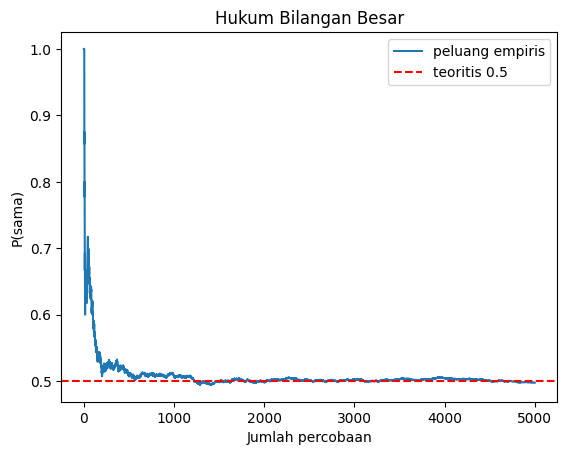


Interpretasi: Rata-rata galat dari 200 ulangan turun terus seiring bertambahnya n, mengikuti pola galat baku teoritis √(0,25/n) 
(nilainya sekitar 0,8 kali galat baku karena yang dirata-ratakan adalah galat mutlak). 
Satu kali simulasi bisa kebetulan pas pada n kecil, sehingga perbandingan yang adil memakai rata-rata banyak ulangan. 
Inilah jawaban pertanyaan 'berapa n yang diperlukan': cukup besar agar fluktuasinya kecil.


In [ ]:
ulangan = 200
for n in [10, 100, 1000, 10000, 100000]:
    galat = [abs(np.mean(rng.integers(0, 2, n) == rng.integers(0, 2, n)) - 0.5) for _ in range(ulangan)]
    print(f"n = {n:>6} -> rata-rata galat = {np.mean(galat):.4f} | teori sqrt(0.25/n) = {math.sqrt(0.25/n):.4f}")

N = 5000
a = rng.integers(0, 2, N); b = rng.integers(0, 2, N)
kumulatif = np.cumsum(a == b) / np.arange(1, N + 1)
plt.plot(kumulatif, label="peluang empiris")
plt.axhline(0.5, color="red", linestyle="--", label="teoritis 0.5")
plt.title("Hukum Bilangan Besar"); plt.xlabel("Jumlah percobaan"); plt.ylabel("P(sama)")
plt.legend(); plt.show()

info(f"""Rata-rata galat dari 200 ulangan turun terus seiring bertambahnya n, mengikuti pola galat baku teoritis √(0,25/n)
(nilainya sekitar 0,8 kali galat baku karena yang dirata-ratakan adalah galat mutlak).
Satu kali simulasi bisa kebetulan pas pada n kecil, sehingga perbandingan yang adil memakai rata-rata banyak ulangan.
Inilah jawaban pertanyaan 'berapa n yang diperlukan': cukup besar agar fluktuasinya kecil.""")


#### EKSPLORASI T4 - Paradoks Monty Hall (simulasi Monte Carlo)
**Soal:** File rahasia disimpan di salah satu dari 3 server. Anda memilih satu server. Sistem lalu membuka satu server lain yang pasti kosong. Apakah sebaiknya tetap pada pilihan awal atau berpindah? Simulasi memodelkan perilaku sistem: server yang dibuka dipilih acak di antara server yang bukan pilihan Anda dan bukan server berisi file.

In [ ]:
N = 100000
benar = rng.integers(0, 3, N)      # server yang berisi file
pilih = rng.integers(0, 3, N)      # pilihan awal pemain
buka = np.empty(N, dtype=int)      # server kosong yang dibuka sistem
for i in range(N):
    kandidat = [d for d in range(3) if d != pilih[i] and d != benar[i]]
    buka[i] = kandidat[rng.integers(0, len(kandidat))]
pindah = 3 - pilih - buka          # server ketiga yang belum dipilih/dibuka

menang_tetap = (pilih == benar).mean()
menang_pindah = (pindah == benar).mean()

print(f"Peluang menang jika TETAP  : {menang_tetap:.4f} (teori 1/3 = {1/3:.4f})")
print(f"Peluang menang jika PINDAH : {menang_pindah:.4f} (teori 2/3 = {2/3:.4f})")

info(f"""Berpindah menang sekitar {menang_pindah:.0%} dibanding {menang_tetap:.0%} jika tetap.
Hasil ini diperoleh dari simulasi perilaku sistem yang membuka server kosong, bukan diasumsikan.

Informasi dari server kosong yang dibuka mengubah peluang bersyarat, sehingga pilihan awal yang hanya 1/3 benar meninggalkan 2/3 peluang pada server yang tersisa.""")

Peluang menang jika TETAP  : 0.3343 (teori 1/3 = 0.3333)
Peluang menang jika PINDAH : 0.6657 (teori 2/3 = 0.6667)

Interpretasi: Berpindah menang sekitar 67% dibanding 33% jika tetap. 
Hasil ini diperoleh dari simulasi perilaku sistem yang membuka server kosong, bukan diasumsikan. 

Informasi dari server kosong yang dibuka mengubah peluang bersyarat, sehingga pilihan awal yang hanya 1/3 benar meninggalkan 2/3 peluang pada server yang tersisa.


#### EKSPLORASI T5 - Birthday Paradox pada Hash Collision
**Soal:** Sebuah tabel hash memiliki m slot. Jika n kunci disimpan secara acak, peluang minimal satu tabrakan (collision) adalah 1 - m!/((m-n)! m^n). Hitung untuk m = 365 dan n = 23, simulasikan, lalu cari n minimum agar peluang tabrakan >= 50% untuk m = 365, 1000, dan 2^32.

m=365, n=23 -> P(tabrakan) teori = 0.5073
Simulasi 20000 kali -> 0.5098
m =        365 -> n minimum untuk P >= 50% : 23
m =      1,000 -> n minimum untuk P >= 50% : 38
m = 4,294,967,296 -> n minimum untuk P >= 50% : 77,164


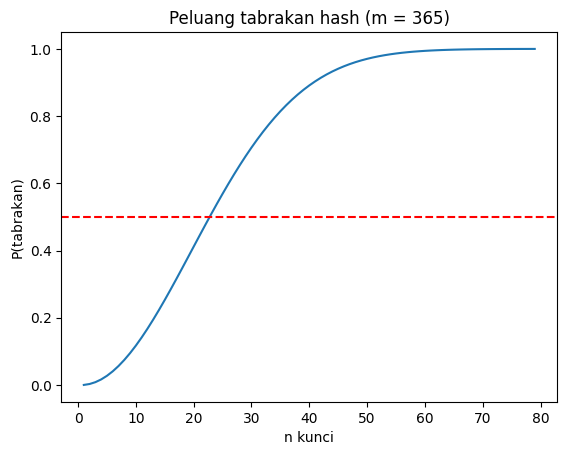


Interpretasi: Hanya 23 kunci pada 365 slot sudah menghasilkan peluang tabrakan sekitar 51%, jauh lebih cepat daripada intuisi. 

Pada ruang hash 32-bit (sekitar 4,3 miliar), tabrakan 50% sudah muncul pada sekitar 77 ribu kunci. 
Ini sebabnya fungsi hash perlu ruang output besar dan tabel hash perlu penanganan collision.


In [ ]:
def p_tabrak(n, m):
    p_aman = 1.0
    for i in range(n):
        p_aman *= (m - i) / m
    return 1 - p_aman

print(f"m=365, n=23 -> P(tabrakan) teori = {p_tabrak(23, 365):.4f}")
N = 20000
sim = sum(len(set(random.randrange(365) for _ in range(23))) < 23 for _ in range(N)) / N   # Python murni (modul random)
print(f"Simulasi {N} kali -> {sim:.4f}")

def n_min(m, target=0.5):
    p_aman, n = 1.0, 0
    while 1 - p_aman < target:
        p_aman *= (m - n) / m
        n += 1
    return n

for m in [365, 1000, 2 ** 32]:
    print(f"m = {m:>10,} -> n minimum untuk P >= 50% : {n_min(m):,}")

ns = np.arange(1, 80)
plt.plot(ns, [p_tabrak(int(k), 365) for k in ns])
plt.axhline(0.5, color="red", linestyle="--")
plt.title("Peluang tabrakan hash (m = 365)"); plt.xlabel("n kunci"); plt.ylabel("P(tabrakan)")
plt.show()

info(f"""Hanya 23 kunci pada 365 slot sudah menghasilkan peluang tabrakan sekitar 51%, jauh lebih cepat daripada intuisi.

Pada ruang hash 32-bit (sekitar 4,3 miliar), tabrakan 50% sudah muncul pada sekitar 77 ribu kunci.
Ini sebabnya fungsi hash perlu ruang output besar dan tabel hash perlu penanganan collision.""")

#### EKSPLORASI T6 - Naive Bayes untuk Filter Spam (pembaruan Bayes berurutan)
**Soal:** 40% email adalah spam. Kata "gratis" muncul di 60% spam dan 5% email normal. Kata "klik" muncul di 50% spam dan 10% email normal. Jika email memuat "gratis", berapa peluang spam? Jika juga memuat "klik" (diasumsikan independen bersyarat seperti Naive Bayes)?

In [ ]:
def update(prior, lik_spam, lik_ham):
    num = prior * lik_spam
    return num / (num + (1 - prior) * lik_ham)

p0 = 0.40
p1 = update(p0, 0.60, 0.05)
p2 = update(p1, 0.50, 0.10)
print(f"Prior P(spam)                 = {p0:.4f}")
print(f"Setelah kata 'gratis'         = {p1:.4f}")
print(f"Setelah kata 'gratis'+'klik'  = {p2:.4f}")

info(f"""Bukti kata 'gratis' menaikkan peluang spam dari {p0:.0%} menjadi {p1:.1%}, dan kata 'klik' menaikkannya lagi menjadi {p2:.1%}.

Inilah prinsip dasar Naive Bayes. Asumsi independen antar kata sering tidak sepenuhnya benar,
sehingga angka ini cukup layak sebagai skor awal, bukan kepastian.""")

Prior P(spam)                 = 0.4000
Setelah kata 'gratis'         = 0.8889
Setelah kata 'gratis'+'klik'  = 0.9756

Interpretasi: Bukti kata 'gratis' menaikkan peluang spam dari 40% menjadi 88.9%, dan kata 'klik' menaikkannya lagi menjadi 97.6%. 

Inilah prinsip dasar Naive Bayes. Asumsi independen antar kata sering tidak sepenuhnya benar, 
sehingga angka ini cukup layak sebagai skor awal, bukan kepastian.


#### EKSPLORASI T7 - Bayes pada Antivirus (base rate) dan Rumus Simbolik dengan sympy
**Soal:** Hanya 1% file di sebuah repositori yang berisi malware. Antivirus mendeteksi malware dengan benar 95% (sensitivitas) dan salah memberi alarm pada 5% file bersih. Jika sebuah file memicu alarm, berapa peluang file itu benar-benar malware?

In [ ]:
prev, se, fp = sp.symbols("prev se fp", positive=True)
posterior = prev * se / (prev * se + (1 - prev) * fp)
print("Rumus simbolik P(malware | alarm) =", posterior)

nilai = posterior.subs({prev: sp.Rational(1, 100), se: sp.Rational(95, 100), fp: sp.Rational(5, 100)})
print("Nilai eksak  =", nilai)
print("Nilai desimal =", round(float(nilai), 4))

N = 1000000
malware = rng.random(N) < 0.01
alarm = np.where(malware, rng.random(N) < 0.95, rng.random(N) < 0.05)
print(f"Simulasi {N} file: P(malware | alarm) = {malware[alarm].mean():.4f}")

info(f"""Hanya {float(nilai):.1%} alarm yang benar-benar malware, walaupun antivirus 95% akurat.

Penyebabnya base rate yang rendah: file bersih jauh lebih banyak sehingga alarm palsunya mendominasi.
Simulasi memberi angka yang mendekati (selisih kecil karena faktor acak).

Artinya hasil alarm perlu diverifikasi lanjut sebelum file dihapus.""")

Rumus simbolik P(malware | alarm) = prev*se/(fp*(1 - prev) + prev*se)
Nilai eksak  = 19/118
Nilai desimal = 0.161
Simulasi 1000000 file: P(malware | alarm) = 0.1601

Interpretasi: Hanya 16.1% alarm yang benar-benar malware, walaupun antivirus 95% akurat. 

Penyebabnya base rate yang rendah: file bersih jauh lebih banyak sehingga alarm palsunya mendominasi. 
Simulasi memberi angka yang mendekati (selisih kecil karena faktor acak). 

Artinya hasil alarm perlu diverifikasi lanjut sebelum file dihapus.


#### EKSPLORASI T8 - Nilai Harapan (Expected Value) Biaya Downtime
**Soal:** Jumlah jam downtime per bulan memiliki sebaran: 0 jam (0,70), 1 jam (0,15), 2 jam (0,08), 4 jam (0,05), 8 jam (0,02). Kerugian Rp5.000.000 per jam. Hitung nilai harapan, varians, dan biaya yang diharapkan.
Syarat distribusi sah: jumlah bobot = 1.

In [ ]:
x = np.array([0, 1, 2, 4, 8])
p = np.array([0.70, 0.15, 0.08, 0.05, 0.02])
print("Jumlah peluang =", p.sum(), "| sah:", np.isclose(p.sum(), 1))

EX = (x * p).sum()
VarX = ((x - EX) ** 2 * p).sum()
biaya = EX * 5_000_000
print(f"E(X)   = {EX:.2f} jam")
print(f"Var(X) = {VarX:.4f} | simpangan baku = {np.sqrt(VarX):.3f} jam")
print(f"Perkiraan kerugian per bulan = Rp{biaya:,.0f}")

info(f"""Rata-rata downtime yang diharapkan {EX:.2f} jam/bulan atau kerugian sekitar Rp{biaya:,.0f}/bulan.

Simpangan baku {np.sqrt(VarX):.2f} jam lebih besar dari rata-ratanya, artinya ada risiko bulan tertentu jauh lebih buruk (hingga 8 jam).

Angka ini membantu menentukan apakah investasi redundansi sebanding dengan kerugian yang diharapkan.""")

Jumlah peluang = 1.0 | sah: True
E(X)   = 0.67 jam
Var(X) = 2.1011 | simpangan baku = 1.450 jam
Perkiraan kerugian per bulan = Rp3,350,000

Interpretasi: Rata-rata downtime yang diharapkan 0.67 jam/bulan atau kerugian sekitar Rp3,350,000/bulan. 

Simpangan baku 1.45 jam lebih besar dari rata-ratanya, artinya ada risiko bulan tertentu jauh lebih buruk (hingga 8 jam). 

Angka ini membantu menentukan apakah investasi redundansi sebanding dengan kerugian yang diharapkan.


#### EKSPLORASI T9 - Distribusi Jumlah Dua Dadu (Counter dan simulasi)
**Soal:** Dua generator angka acak masing-masing menghasilkan bilangan 1-6. Tentukan distribusi jumlah keduanya, peluang jumlah 7, dan bandingkan dengan simulasi 100.000 kali.

Jumlah | Teori   | Simulasi
     2 | 0.0278  | 0.0279   (teori 1/36)
     3 | 0.0556  | 0.0566   (teori 1/18)
     4 | 0.0833  | 0.0844   (teori 1/12)
     5 | 0.1111  | 0.1122   (teori 1/9)
     6 | 0.1389  | 0.1387   (teori 5/36)
     7 | 0.1667  | 0.1662   (teori 1/6)
     8 | 0.1389  | 0.1383   (teori 5/36)
     9 | 0.1111  | 0.1095   (teori 1/9)
    10 | 0.0833  | 0.0843   (teori 1/12)
    11 | 0.0556  | 0.0545   (teori 1/18)
    12 | 0.0278  | 0.0275   (teori 1/36)


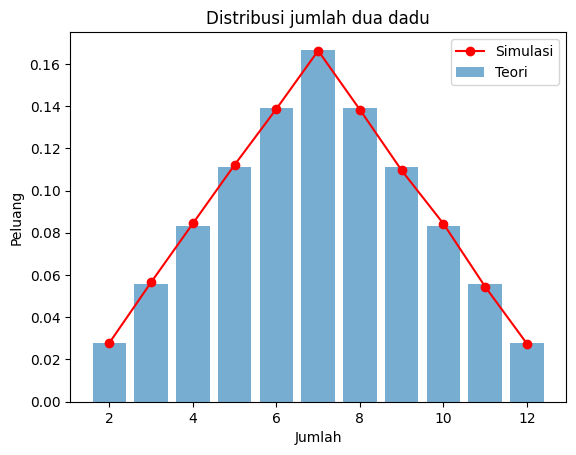


Interpretasi: Jumlah 7 paling mungkin dengan peluang 1/6 = 0.1667, sedangkan 2 dan 12 hanya 1/36. 

Simulasi hampir berimpit dengan teori sehingga model ruang sampel yang dipakai benar.


In [ ]:
ruang = list(itertools.product(range(1, 7), repeat=2))
hitung = Counter(a + b for a, b in ruang)
teori = {j: Fraction(c, len(ruang)) for j, c in sorted(hitung.items())}

sim = Counter((rng.integers(1, 7, 100000) + rng.integers(1, 7, 100000)).tolist())
print("Jumlah | Teori   | Simulasi")
for j in range(2, 13):
    print(f"{j:>6} | {float(teori[j]):.4f}  | {sim[j]/100000:.4f}   (teori {teori[j]})")

plt.bar(list(teori.keys()), [float(v) for v in teori.values()], alpha=0.6, label="Teori")
plt.plot(range(2, 13), [sim[j] / 100000 for j in range(2, 13)], "ro-", label="Simulasi")
plt.legend(); plt.title("Distribusi jumlah dua dadu"); plt.xlabel("Jumlah"); plt.ylabel("Peluang")
plt.show()

info(f"""Jumlah 7 paling mungkin dengan peluang {teori[7]} = {float(teori[7]):.4f}, sedangkan 2 dan 12 hanya {teori[2]}.

Simulasi hampir berimpit dengan teori sehingga model ruang sampel yang dipakai benar.""")